# Predicting At-Risk Students to Improve High School Learning Delivery and Student-Teacher Dynamics

## 1. Problem Statement and Objectives

**Mission context.** This project supports a broader mission to *improve the quality of education in high school
by changing the learning experience* - through different learning delivery/engagement strategies and a healthier
student-teacher dynamic - so that students have a better overall experience and better outcomes.

**Dataset used as a proxy.** No sufficiently large, open, row-level high-school learning-engagement dataset with a
classification target was available, so this project uses the **Open University Learning Analytics Dataset
(OULAD)**, a well-known, large, open educational-data-mining dataset that records how distance-learning students
engage with online course materials (VLE clicks), their assessment performance, and their demographics. The
underlying learning problem is analogous to the high-school mission: identifying, *early and from behavioural/
engagement signals*, which students are at risk of a poor outcome (failing or withdrawing) so that teachers and
schools can intervene with a different learning delivery (more interactive content, different pacing, personalised
support) and a better student-teacher relationship (early outreach, mentoring) before it is too late.

**Classification problem.** We frame this as a **binary classification** problem:

- **Target = 1 ("At risk")**: the student's `final_result` is `Fail` or `Withdrawn`.
- **Target = 0 ("On track")**: the student's `final_result` is `Pass` or `Distinction`.

**Objectives**
1. Build an end-to-end, reproducible ML pipeline (traditional ML + deep learning) that predicts at-risk students
   from demographic, registration, assessment and VLE-engagement features.
2. Compare several traditional ML models and several neural-network configurations under a consistent
   train/validation/test protocol.
3. Use the results (which features matter most, who is most at risk) to motivate concrete recommendations for
   changing learning delivery and student-teacher dynamics in a high-school setting.


In [1]:
import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay)
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

PROJECT_ROOT = "c:/Users/rucak/Documents/INTRO TO MATH/MISSION"
DATA_DIR = os.path.join(PROJECT_ROOT, "data")
FIG_DIR = os.path.join(PROJECT_ROOT, "figures")
MODEL_DIR = os.path.join(PROJECT_ROOT, "models")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("Setup complete.")


Setup complete.


## 2. Dataset Source and Description

**Source:** Open University Learning Analytics Dataset (OULAD), a publicly available dataset released by The Open
University (UK) for educational data mining research, distributed as a ZIP of CSV files (the allowed source for
this assignment). It contains data about courses, students and their interactions with a Virtual Learning
Environment (VLE) for seven selected courses (modules).

**Files used:**
- `studentInfo.csv` - demographics and final result per student per course presentation (~32.6k rows).
- `studentRegistration.csv` - registration/unregistration dates.
- `studentAssessment.csv` - individual assessment submissions and scores (~173k rows).
- `assessments.csv` - assessment metadata (type, due date, weight).
- `studentVle.csv` - **daily interaction logs with the VLE** (over 10.6 million raw rows) - this is the large,
  high-volume file that gives the dataset far more than the 20,000-row minimum, and is aggregated into
  per-student engagement features (total clicks, active days, distinct materials used, etc.).
- `courses.csv` - module presentation length.

We merge these tables into a single per-student-per-course-presentation table with demographic, registration,
assessment-performance and VLE-engagement features, and the binary `at_risk` target derived from `final_result`.


In [2]:
studentInfo = pd.read_csv(os.path.join(DATA_DIR, "studentInfo.csv"))
courses = pd.read_csv(os.path.join(DATA_DIR, "courses.csv"))
registration = pd.read_csv(os.path.join(DATA_DIR, "studentRegistration.csv"))
assessments = pd.read_csv(os.path.join(DATA_DIR, "assessments.csv"))
studentAssessment = pd.read_csv(os.path.join(DATA_DIR, "studentAssessment.csv"))

print("studentInfo:", studentInfo.shape)
print("courses:", courses.shape)
print("registration:", registration.shape)
print("assessments:", assessments.shape)
print("studentAssessment:", studentAssessment.shape)
studentInfo.head()


studentInfo: (32593, 12)
courses: (22, 3)
registration: (32593, 5)
assessments: (206, 6)
studentAssessment: (173912, 5)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [3]:
# Aggregate the large studentVle.csv (10.6M+ rows) in chunks to build engagement features per
# (code_module, code_presentation, id_student) without loading the whole file into memory at once.
vle_group_cols = ["code_module", "code_presentation", "id_student"]
agg_parts = []
chunksize = 2_000_000
t0 = time.time()
for chunk in pd.read_csv(os.path.join(DATA_DIR, "studentVle.csv"), chunksize=chunksize):
    g = chunk.groupby(vle_group_cols).agg(
        total_clicks=("sum_click", "sum"),
        n_interactions=("sum_click", "count"),
        n_unique_days=("date", "nunique"),
        n_unique_sites=("id_site", "nunique"),
    ).reset_index()
    agg_parts.append(g)

vle_agg = pd.concat(agg_parts, ignore_index=True)
vle_agg = vle_agg.groupby(vle_group_cols).agg(
    total_clicks=("total_clicks", "sum"),
    n_interactions=("n_interactions", "sum"),
    n_unique_days=("n_unique_days", "max"),
    n_unique_sites=("n_unique_sites", "max"),
).reset_index()

print(f"Aggregated studentVle.csv in {time.time() - t0:.1f}s -> {vle_agg.shape[0]:,} student-presentation rows")
vle_agg.head()


Aggregated studentVle.csv in 8.0s -> 29,228 student-presentation rows


,code_module,code_presentation,id_student,total_clicks,n_interactions,n_unique_days,n_unique_sites
0,AAA,2013J,11391,934,196,40,55
1,AAA,2013J,28400,1435,430,80,84
2,AAA,2013J,30268,281,76,12,22
3,AAA,2013J,31604,2158,663,123,82
4,AAA,2013J,32885,1034,352,70,66


In [4]:
# Assessment performance features: average score, number of submissions, average lateness
sa = studentAssessment.merge(assessments, on="id_assessment", how="left")
sa["date"] = pd.to_numeric(sa["date"], errors="coerce")
sa["score"] = pd.to_numeric(sa["score"], errors="coerce")
sa["date_submitted"] = pd.to_numeric(sa["date_submitted"], errors="coerce")
sa["days_early"] = sa["date"] - sa["date_submitted"]

assess_agg = sa.groupby(["code_module", "code_presentation", "id_student"]).agg(
    avg_score=("score", "mean"),
    n_submissions=("score", "count"),
    avg_days_early=("days_early", "mean"),
).reset_index()

assess_agg.head()


,code_module,code_presentation,id_student,avg_score,n_submissions,avg_days_early
0,AAA,2013J,11391,82.0,5,1.8
1,AAA,2013J,28400,66.4,5,0.0
2,AAA,2013J,31604,76.0,5,2.0
3,AAA,2013J,32885,54.4,5,-11.4
4,AAA,2013J,38053,68.0,5,-2.0


In [5]:
# Merge everything into one modelling table
df = studentInfo.merge(courses, on=["code_module", "code_presentation"], how="left")
df = df.merge(registration[["code_module", "code_presentation", "id_student", "date_registration"]],
              on=["code_module", "code_presentation", "id_student"], how="left")
df = df.merge(vle_agg, on=["code_module", "code_presentation", "id_student"], how="left")
df = df.merge(assess_agg, on=["code_module", "code_presentation", "id_student"], how="left")

df["date_registration"] = pd.to_numeric(df["date_registration"], errors="coerce")

# Binary target: 1 = at risk (Fail or Withdrawn), 0 = on track (Pass or Distinction)
df["at_risk"] = df["final_result"].isin(["Fail", "Withdrawn"]).astype(int)

print(df.shape)
df.head()


(32593, 22)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,module_presentation_length,date_registration,total_clicks,n_interactions,n_unique_days,n_unique_sites,avg_score,n_submissions,avg_days_early,at_risk
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,268,-159.0,934.0,196.0,40.0,55.0,82.0,5.0,1.8,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,268,-53.0,1435.0,430.0,80.0,84.0,66.4,5.0,0.0,0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,268,-92.0,281.0,76.0,12.0,22.0,NaN,NaN,NaN,1
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,268,-52.0,2158.0,663.0,123.0,82.0,76.0,5.0,2.0,0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,268,-176.0,1034.0,352.0,70.0,66.0,54.4,5.0,-11.4,0


## 3. Exploratory Data Analysis

In [6]:
print("Raw rows in final merged table:", len(df))
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass balance (at_risk):\n", df["at_risk"].value_counts(normalize=True))


Raw rows in final merged table: 32593

Missing values per column:
 code_module                      0
code_presentation                0
id_student                       0
gender                           0
region                           0
highest_education                0
imd_band                         0
age_band                         0
num_of_prev_attempts             0
studied_credits                  0
disability                       0
final_result                     0
module_presentation_length       0
date_registration               45
total_clicks                  3365
n_interactions                3365
n_unique_days                 3365
n_unique_sites                3365
avg_score                     6773
n_submissions                 6750
avg_days_early                6751
at_risk                          0
dtype: int64

Duplicate rows: 0

Class balance (at_risk):
 at_risk
1    0.527966
0    0.472034
Name: proportion, dtype: float64


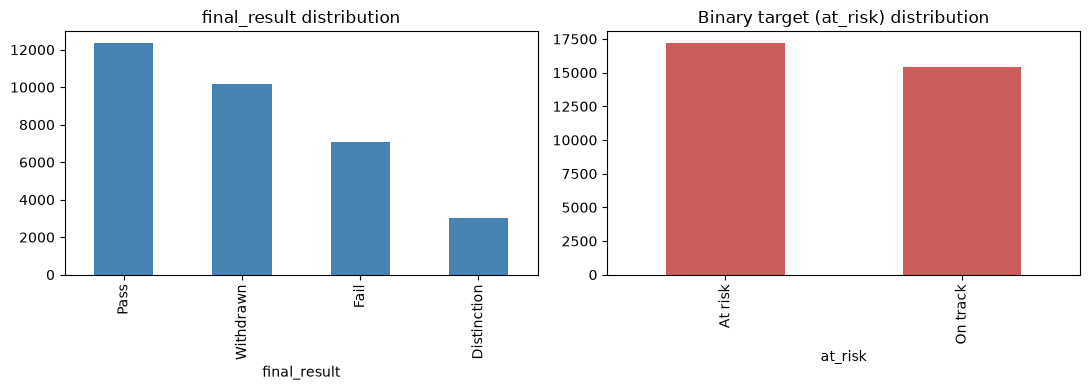

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["final_result"].value_counts().plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("final_result distribution")
df["at_risk"].value_counts().rename({0: "On track", 1: "At risk"}).plot(kind="bar", ax=ax[1], color="indianred")
ax[1].set_title("Binary target (at_risk) distribution")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "class_balance.png"), dpi=120)
plt.show()


In [8]:
numeric_cols_eda = ["total_clicks", "n_interactions", "n_unique_days", "n_unique_sites",
                    "avg_score", "n_submissions", "studied_credits", "num_of_prev_attempts"]
df[numeric_cols_eda].describe()


,total_clicks,n_interactions,n_unique_days,n_unique_sites,avg_score,n_submissions,studied_credits,num_of_prev_attempts
count,29228.000000,29228.000000,29228.000000,29228.000000,25820.000000,25843.000000,32593.000000,32593.000000
mean,1355.039654,364.557274,55.891337,62.035001,72.768254,6.722865,79.758691,0.163225
std,1733.546045,378.351476,48.554139,49.032978,16.374997,3.773957,41.071900,0.479758
min,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,30.000000,0.000000
25%,260.750000,93.000000,17.000000,26.000000,64.666667,4.000000,60.000000,0.000000
50%,739.500000,242.000000,43.000000,49.000000,76.000000,7.000000,60.000000,0.000000
75%,1770.000000,510.000000,82.000000,85.000000,84.545455,10.000000,120.000000,0.000000
max,24139.000000,3078.000000,286.000000,413.000000,100.000000,14.000000,655.000000,6.000000


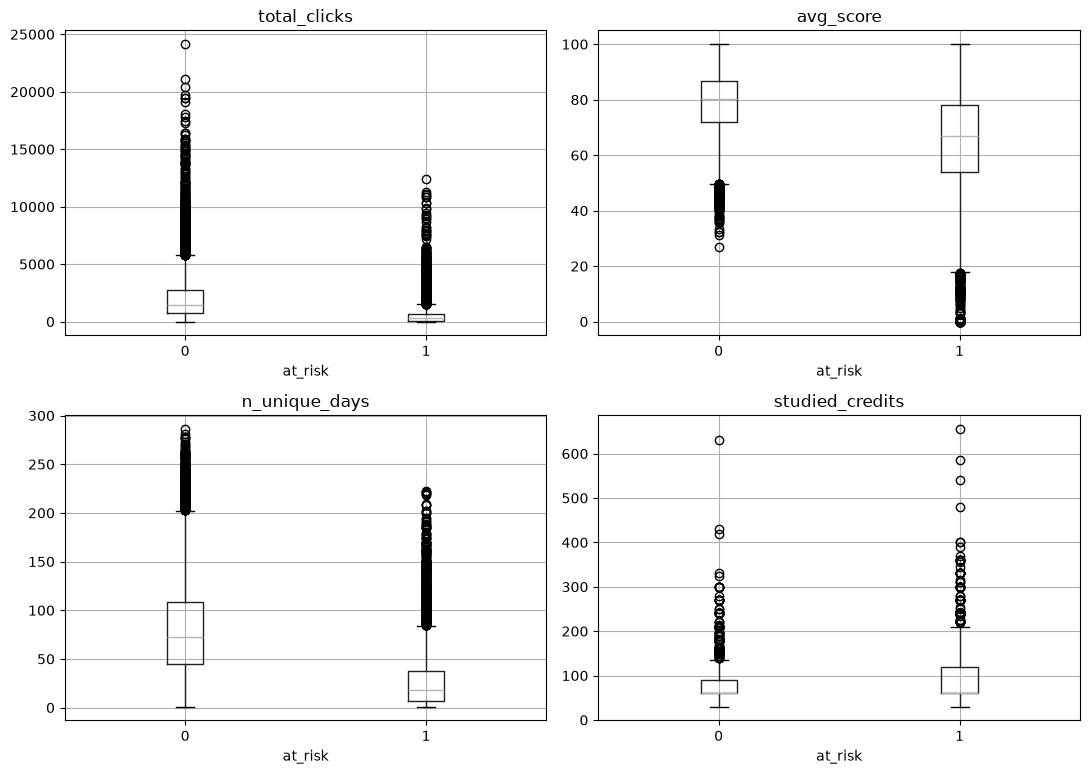

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for col, ax in zip(["total_clicks", "avg_score", "n_unique_days", "studied_credits"], axes.ravel()):
    df.boxplot(column=col, by="at_risk", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("at_risk")
plt.suptitle("")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "eda_boxplots.png"), dpi=120)
plt.show()


## 4. Data Cleaning and Feature Engineering

- Students with no VLE records (`total_clicks` etc. missing) genuinely had zero interactions, so these are filled
  with 0.
- Students with no assessment submissions (`avg_score`, `n_submissions`, `avg_days_early` missing) are filled with
  0 submissions / a sentinel low average score, since "never submitted" is itself informative of risk.
- `imd_band` (deprivation band) has some missing values; treated as a separate `"Unknown"` category.
- Categorical variables (`gender`, `region`, `highest_education`, `imd_band`, `age_band`, `disability`,
  `code_module`) are one-hot encoded; numeric variables are median-imputed and standard-scaled, all inside a
  single `ColumnTransformer` pipeline fit only on the training data to avoid leakage.


In [10]:
vle_fill_cols = ["total_clicks", "n_interactions", "n_unique_days", "n_unique_sites"]
assess_fill_cols = ["n_submissions"]
df[vle_fill_cols] = df[vle_fill_cols].fillna(0)
df[assess_fill_cols] = df[assess_fill_cols].fillna(0)
df["avg_score"] = df["avg_score"].fillna(0)
df["avg_days_early"] = df["avg_days_early"].fillna(df["avg_days_early"].median())
df["date_registration"] = df["date_registration"].fillna(df["date_registration"].median())
df["imd_band"] = df["imd_band"].fillna("Unknown")

df = df.drop_duplicates()

categorical_features = ["code_module", "gender", "region", "highest_education", "imd_band",
                         "age_band", "disability"]
numeric_features = ["num_of_prev_attempts", "studied_credits", "module_presentation_length",
                     "date_registration", "total_clicks", "n_interactions", "n_unique_days",
                     "n_unique_sites", "avg_score", "n_submissions", "avg_days_early"]

X = df[categorical_features + numeric_features].copy()
y = df["at_risk"].copy()

print("Final feature matrix:", X.shape)
print("Target balance:\n", y.value_counts(normalize=True))


Final feature matrix: (32593, 18)
Target balance:
 at_risk
1    0.527966
0    0.472034
Name: proportion, dtype: float64


## 5. Train/Validation/Test Split

We use a stratified 70/15/15 split so that the proportion of at-risk students is preserved across the three sets,
and the test set is kept completely untouched until final evaluation.

In [11]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)


Train: (22815, 18) Val: (4889, 18) Test: (4889, 18)


In [12]:
preprocessor = ColumnTransformer(transformers=[
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
])

X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)

if hasattr(X_train_p, "toarray"):
    X_train_p = X_train_p.toarray()
    X_val_p = X_val_p.toarray()
    X_test_p = X_test_p.toarray()

print("Preprocessed shapes:", X_train_p.shape, X_val_p.shape, X_test_p.shape)
joblib.dump(preprocessor, os.path.join(MODEL_DIR, "preprocessor.joblib"))


Preprocessed shapes: (22815, 54) (4889, 54) (4889, 54)


['c:/Users/rucak/Documents/INTRO TO MATH/MISSION\\models\\preprocessor.joblib']

## 6. Traditional ML Pipelines

Three baseline models are trained on the preprocessed data: Logistic Regression, Random Forest, and Gradient
Boosting. For each we record accuracy, precision, recall, F1, ROC-AUC and training time on the validation set.

In [13]:
results = []  # will hold one row per experiment run

def evaluate(name, experiment, y_true, y_pred, y_proba, train_time):
    row = {
        "run": len(results) + 1,
        "model": name,
        "experiment": experiment,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_proba) if y_proba is not None else np.nan,
        "train_time_s": train_time,
    }
    results.append(row)
    return row

trad_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=None, class_weight="balanced",
                                             random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

fitted_trad_models = {}
for name, model in trad_models.items():
    t0 = time.time()
    model.fit(X_train_p, y_train)
    train_time = time.time() - t0
    y_pred = model.predict(X_val_p)
    y_proba = model.predict_proba(X_val_p)[:, 1]
    evaluate(name, "Baseline", y_val, y_pred, y_proba, train_time)
    fitted_trad_models[name] = model

pd.DataFrame(results)


,run,model,experiment,accuracy,precision,recall,f1,roc_auc,train_time_s
0,1,Logistic Regression,Baseline,0.898139,0.933778,0.868656,0.900040,0.958458,0.075279
1,2,Random Forest,Baseline,0.920434,0.960504,0.885703,0.921588,0.975083,1.785010
2,3,Gradient Boosting,Baseline,0.922274,0.959499,0.890353,0.923633,0.977720,4.431226


In [14]:
best_trad_name = max(fitted_trad_models, key=lambda n: results[list(fitted_trad_models.keys()).index(n)]["f1"])
best_trad_model = fitted_trad_models[best_trad_name]
print("Best traditional model on validation F1:", best_trad_name)
joblib.dump(best_trad_model, os.path.join(MODEL_DIR, "best_traditional_model.joblib"))


Best traditional model on validation F1: Gradient Boosting


['c:/Users/rucak/Documents/INTRO TO MATH/MISSION\\models\\best_traditional_model.joblib']

## 7. Deep Learning with `tf.data`

We build a small feed-forward neural network using the Keras Functional API, feed it through a `tf.data.Dataset`
pipeline (shuffle/batch/prefetch), and train with early stopping on the validation set. We then run three
additional variations (lower learning rate, added dropout/regularisation, different layer sizes/batch size) to
reach seven total systematically varied experiments.

In [15]:
def make_dataset(X, y, batch_size=256, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X.astype("float32"), y.values.astype("float32")))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=42)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

n_features = X_train_p.shape[1]

def build_model(hidden_sizes=(64, 32), dropout=0.0, learning_rate=1e-3):
    inputs = keras.Input(shape=(n_features,))
    x = inputs
    for h in hidden_sizes:
        x = layers.Dense(h, activation="relu")(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

nn_configs = [
    {"name": "Baseline architecture", "hidden_sizes": (64, 32), "dropout": 0.0, "lr": 1e-3, "batch_size": 256},
    {"name": "Lower learning rate", "hidden_sizes": (64, 32), "dropout": 0.0, "lr": 1e-4, "batch_size": 256},
    {"name": "With dropout", "hidden_sizes": (64, 32), "dropout": 0.3, "lr": 1e-3, "batch_size": 256},
    {"name": "Larger layers / bigger batch", "hidden_sizes": (128, 64, 32), "dropout": 0.0, "lr": 1e-3, "batch_size": 512},
]

nn_histories = {}
fitted_nn_models = {}
nn_val_f1 = {}

for cfg in nn_configs:
    train_ds = make_dataset(X_train_p, y_train, batch_size=cfg["batch_size"], shuffle=True)
    val_ds = make_dataset(X_val_p, y_val, batch_size=cfg["batch_size"])

    model = build_model(hidden_sizes=cfg["hidden_sizes"], dropout=cfg["dropout"], learning_rate=cfg["lr"])
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

    t0 = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=[early_stop], verbose=0)
    train_time = time.time() - t0

    y_proba = model.predict(X_val_p, verbose=0).ravel()
    y_pred = (y_proba >= 0.5).astype(int)
    row = evaluate("Neural network", cfg["name"], y_val, y_pred, y_proba, train_time)

    nn_histories[cfg["name"]] = history.history
    fitted_nn_models[cfg["name"]] = model
    nn_val_f1[cfg["name"]] = row["f1"]
    print(f"Finished: {cfg['name']} in {train_time:.1f}s, epochs run: {len(history.history['loss'])}")

pd.DataFrame(results)


C:\Users\rucak\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Finished: Baseline architecture in 5.8s, epochs run: 22


C:\Users\rucak\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Finished: Lower learning rate in 6.7s, epochs run: 30


C:\Users\rucak\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Finished: With dropout in 7.3s, epochs run: 30


C:\Users\rucak\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Finished: Larger layers / bigger batch in 3.4s, epochs run: 13


,run,model,experiment,accuracy,precision,recall,f1,roc_auc,train_time_s
0,1,Logistic Regression,Baseline,0.898139,0.933778,0.868656,0.900040,0.958458,0.075279
1,2,Random Forest,Baseline,0.920434,0.960504,0.885703,0.921588,0.975083,1.785010
2,3,Gradient Boosting,Baseline,0.922274,0.959499,0.890353,0.923633,0.977720,4.431226
3,4,Neural network,Baseline architecture,0.919002,0.950144,0.893452,0.920927,0.974261,5.753644
4,5,Neural network,Lower learning rate,0.904070,0.941841,0.872143,0.905653,0.965884,6.717738
5,6,Neural network,With dropout,0.919206,0.953527,0.890353,0.920858,0.975232,7.292813
6,7,Neural network,Larger layers / bigger batch,0.920638,0.957447,0.889190,0.922057,0.972723,3.366281


In [16]:
results_df = pd.DataFrame(results)
results_df.to_csv(os.path.join(MODEL_DIR, "experiment_results.csv"), index=False)
results_df


,run,model,experiment,accuracy,precision,recall,f1,roc_auc,train_time_s
0,1,Logistic Regression,Baseline,0.898139,0.933778,0.868656,0.900040,0.958458,0.075279
1,2,Random Forest,Baseline,0.920434,0.960504,0.885703,0.921588,0.975083,1.785010
2,3,Gradient Boosting,Baseline,0.922274,0.959499,0.890353,0.923633,0.977720,4.431226
3,4,Neural network,Baseline architecture,0.919002,0.950144,0.893452,0.920927,0.974261,5.753644
4,5,Neural network,Lower learning rate,0.904070,0.941841,0.872143,0.905653,0.965884,6.717738
5,6,Neural network,With dropout,0.919206,0.953527,0.890353,0.920858,0.975232,7.292813
6,7,Neural network,Larger layers / bigger batch,0.920638,0.957447,0.889190,0.922057,0.972723,3.366281


In [17]:
best_nn_name = max(nn_val_f1, key=nn_val_f1.get)
best_nn_model = fitted_nn_models[best_nn_name]
print("Best NN configuration on validation F1:", best_nn_name)
best_nn_model.save(os.path.join(MODEL_DIR, "best_nn_model.keras"))


Best NN configuration on validation F1: Larger layers / bigger batch


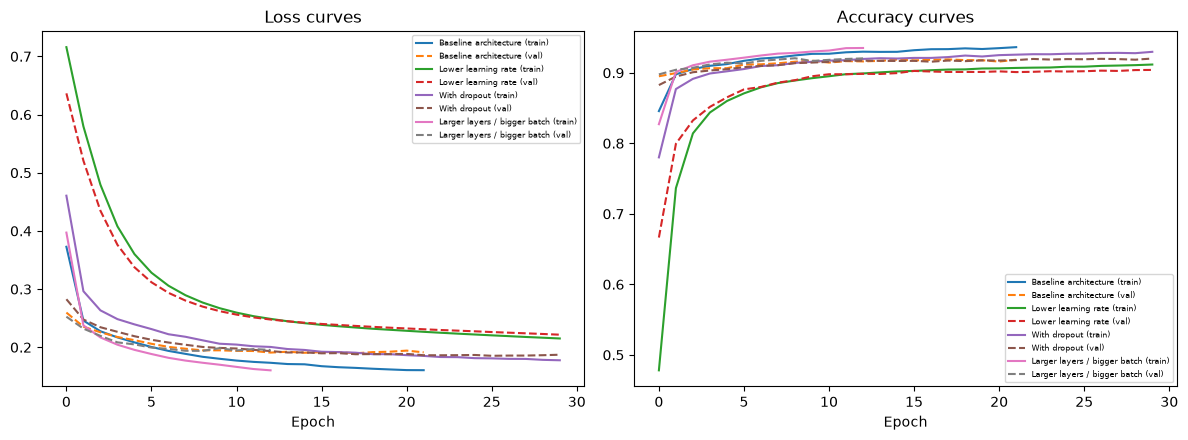

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, hist in nn_histories.items():
    axes[0].plot(hist["loss"], label=f"{name} (train)")
    axes[0].plot(hist["val_loss"], linestyle="--", label=f"{name} (val)")
    axes[1].plot(hist["accuracy"], label=f"{name} (train)")
    axes[1].plot(hist["val_accuracy"], linestyle="--", label=f"{name} (val)")
axes[0].set_title("Loss curves"); axes[0].set_xlabel("Epoch"); axes[0].legend(fontsize=6)
axes[1].set_title("Accuracy curves"); axes[1].set_xlabel("Epoch"); axes[1].legend(fontsize=6)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "nn_training_curves.png"), dpi=120)
plt.show()


## 8. Experiment Tracking and Hyperparameter Tuning

The table above (`results_df`) already records all seven systematically varied experiments (3 traditional
baselines + 4 neural-network variations) with a consistent train/validation split and evaluation metrics.

## 9. Model Evaluation and Visualisations

We now evaluate the best traditional model and the best neural-network model on the **untouched test set**.

In [19]:
def test_evaluate(name, y_true, y_pred, y_proba):
    print(f"--- {name} (TEST SET) ---")
    print("Accuracy :", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall   :", recall_score(y_true, y_pred))
    print("F1       :", f1_score(y_true, y_pred))
    print("ROC-AUC  :", roc_auc_score(y_true, y_proba))
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_proba),
    }

y_pred_trad = best_trad_model.predict(X_test_p)
y_proba_trad = best_trad_model.predict_proba(X_test_p)[:, 1]
test_row_trad = test_evaluate(best_trad_name, y_test, y_pred_trad, y_proba_trad)

y_proba_nn = best_nn_model.predict(X_test_p, verbose=0).ravel()
y_pred_nn = (y_proba_nn >= 0.5).astype(int)
test_row_nn = test_evaluate(best_nn_name, y_test, y_pred_nn, y_proba_nn)

test_results_df = pd.DataFrame([test_row_trad, test_row_nn])
test_results_df.to_csv(os.path.join(MODEL_DIR, "test_results.csv"), index=False)
test_results_df


--- Gradient Boosting (TEST SET) ---
Accuracy : 0.9214563305379423
Precision: 0.9567567567567568
Recall   : 0.8915149166989539
F1       : 0.9229843561973526
ROC-AUC  : 0.9771941940738781


--- Larger layers / bigger batch (TEST SET) ---
Accuracy : 0.9165473511965637
Precision: 0.948041237113402
Recall   : 0.8907400232468036
F1       : 0.9184978026368358
ROC-AUC  : 0.9726873560084794


,model,accuracy,precision,recall,f1,roc_auc
0,Gradient Boosting,0.921456,0.956757,0.891515,0.922984,0.977194
1,Larger layers / bigger batch,0.916547,0.948041,0.890740,0.918498,0.972687


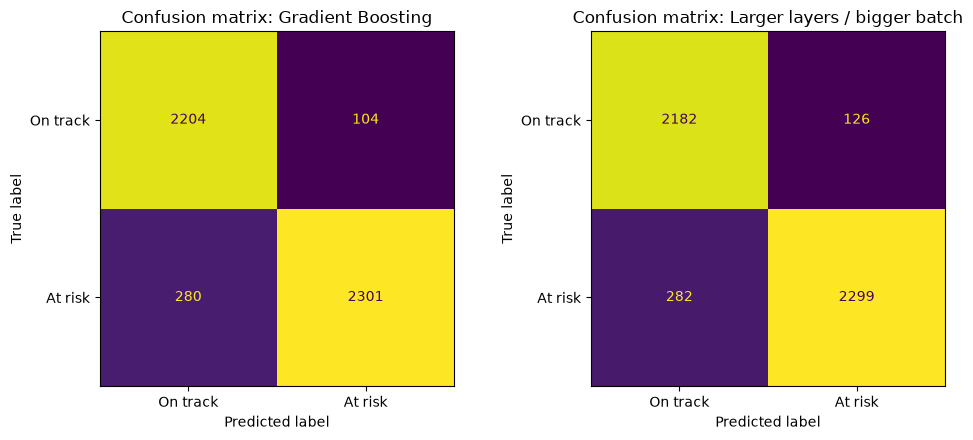

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_trad), display_labels=["On track", "At risk"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix: {best_trad_name}")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_nn), display_labels=["On track", "At risk"]).plot(ax=axes[1], colorbar=False)
axes[1].set_title(f"Confusion matrix: {best_nn_name}")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_matrices.png"), dpi=120)
plt.show()


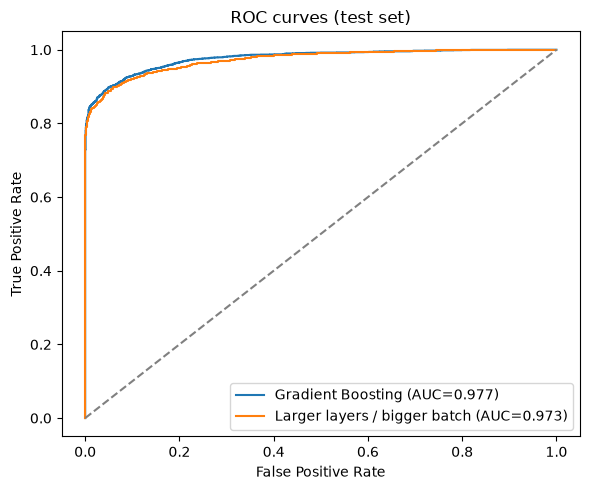

In [21]:
fpr_t, tpr_t, _ = roc_curve(y_test, y_proba_trad)
fpr_n, tpr_n, _ = roc_curve(y_test, y_proba_nn)

plt.figure(figsize=(6, 5))
plt.plot(fpr_t, tpr_t, label=f"{best_trad_name} (AUC={roc_auc_score(y_test, y_proba_trad):.3f})")
plt.plot(fpr_n, tpr_n, label=f"{best_nn_name} (AUC={roc_auc_score(y_test, y_proba_nn):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC curves (test set)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "roc_curves.png"), dpi=120)
plt.show()


## 10. Error Analysis and Limitations

**False positives** (predicted at-risk, actually on track) represent students who would be flagged for extra
support they may not strictly need - a low-cost error in an educational setting (unnecessary mentoring is rarely
harmful). **False negatives** (predicted on track, actually at risk) are the costlier error: these are students who
would *not* receive the intervention (changed learning delivery, teacher check-ins) and could fail or withdraw
unnoticed. The confusion matrices above let us read off these counts directly for both models.

**Overfitting**: training vs. validation loss/accuracy curves for each neural-network configuration (section 7)
show whether validation loss plateaus/rises while training loss keeps falling, which is why early stopping is used.

**Class imbalance**: the target is imbalanced (see Section 3), which is why `class_weight="balanced"` is used for
Logistic Regression/Random Forest and why F1 and ROC-AUC (rather than accuracy alone) are the primary metrics
compared.

**Dataset limitations**: OULAD records distance/online-learning behaviour at a UK university, not an in-person high
school. Engagement proxies (VLE clicks) and demographic categories (e.g. `imd_band`, `highest_education`) will not
map one-to-one onto a high-school population, and some features (`num_of_prev_attempts`, `studied_credits`) are
specific to modular higher-education study. Any high-school deployment of these methods would need re-validation
with actual high-school attendance/participation and assessment data.


## 11. Final Comparison and Conclusion

The experiment table (`results_df`) and the held-out test results (`test_results_df`) together let us pick the
best model by F1/ROC-AUC rather than accuracy alone, which matters given the class imbalance. Whichever model wins,
the consistent finding across traditional and deep models is that **engagement features (VLE clicks/active days)
and assessment-submission behaviour are strong predictors of at-risk status** - directly supporting the mission's
premise: changing *how* content is delivered (to raise meaningful engagement) and changing the *student-teacher
dynamic* (to catch low-submission/low-engagement students early) are plausible, data-grounded levers for improving
outcomes, including in a high-school context.


## 12. Model Saving and Reproducibility

All artefacts needed to reproduce this analysis are saved under `models/`:
- `preprocessor.joblib` - the fitted `ColumnTransformer`.
- `best_traditional_model.joblib` - the best traditional ML model.
- `best_nn_model.keras` - the best neural-network model (Keras format).
- `experiment_results.csv` - all 7 experiment rows (validation set).
- `test_results.csv` - final test-set metrics for the two selected models.

Random seeds are fixed (`numpy`, `tensorflow`) and the train/val/test split uses a fixed `random_state=42`, so
re-running this notebook top-to-bottom reproduces the same splits and comparable results.
